In [2]:
from common import Cubo, AjusteSARIMAX
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.statespace.sarimax import SARIMAX
import numpy as np
import statsmodels.api as sm
from statsmodels.tsa.stattools import grangercausalitytests

In [3]:
vegetacion_cubo = Cubo("data/vegetacion.csv", "data/tiempo.csv")
temperatura_cubo = Cubo("data/temperaturas.csv", "data/tiempo.csv")

## Gráfico de Correlación entre Temperaturas y Vegetación - Serie [0][0]

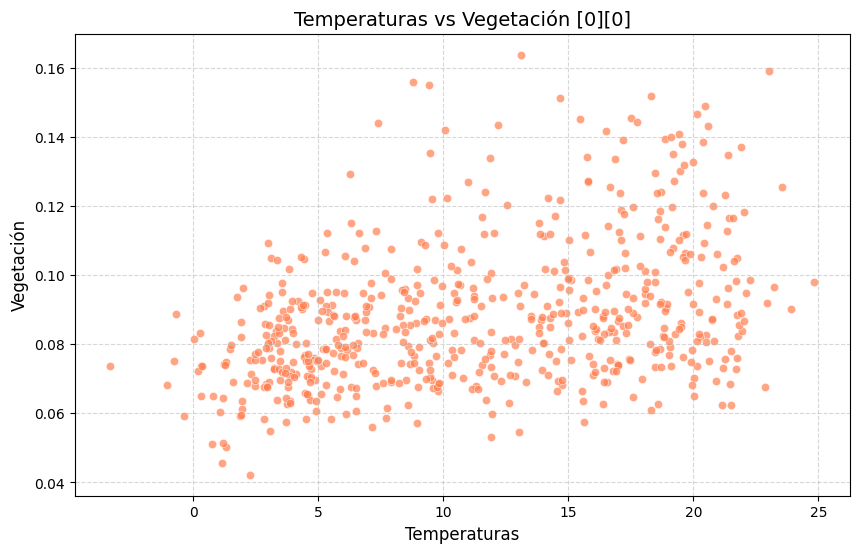

In [4]:

plt.figure(figsize=(10, 6))
sns.scatterplot(x=temperatura_cubo.datos[0, 0, :], y=vegetacion_cubo.datos[0,0,:], alpha=0.7, color='coral', edgecolor='w')

plt.title('Temperaturas vs Vegetación [0][0]', fontsize=14)
plt.xlabel('Temperaturas', fontsize=12)
plt.ylabel('Vegetación', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)


plt.show()

## Modelo SARIMAX

In [5]:
p, i, q = 3, 0, 0
P, I, Q, s = 0, 0, 0, 23

# Ajustar el modelo
modelo = SARIMAX(
    vegetacion_cubo.datos[0, 0, :], exog=temperatura_cubo.datos[0, 0, :],
    order=(p, i, q),
    seasonal_order=(P, I, Q, s),
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
)
ajuste = modelo.fit(disp=False)
print(ajuste.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  604
Model:               SARIMAX(3, 0, 0)   Log Likelihood                1697.576
Date:                Sun, 25 Oct 2026   AIC                          -3385.151
Time:                        19:10:40   BIC                          -3363.158
Sample:                             0   HQIC                         -3376.590
                                - 604                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0009      0.000      5.241      0.000       0.001       0.001
ar.L1          0.5578      0.037     14.906      0.000       0.484       0.631
ar.L2          0.2544      0.035      7.179      0.0

### Residuos

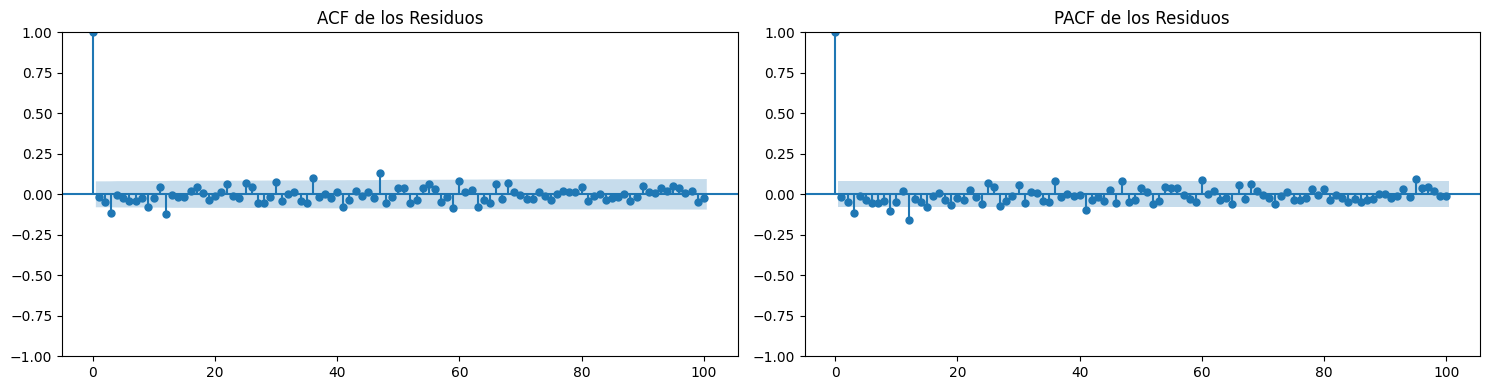

In [6]:
ajuste_sarimax = AjusteSARIMAX(vegetacion_cubo.datos[0, 0, :], ajuste, "Ajuste SARIMAX")
ajuste_sarimax.graficos_residuos()

In [7]:
# Omitimos las primeras 50 observaciones para evitar la distorsión del período de inicialización con s=23
class GraficosAjuste:
    def ajuste_vs_datos(self, tiempo, x, y, ajuste, start_idx=46):

        tiempo_grafico = tiempo[start_idx:]
        prediccion = ajuste.get_prediction(exog=x)
        pred_media = prediccion.predicted_mean
        pred_ci = prediccion.conf_int(alpha=0.05)

        plt.figure(figsize=(15, 6))
        # Puntos en bruto de la serie original en azul
        plt.scatter(tiempo_grafico, np.array(y)[start_idx:], color='blue', alpha=0.5, s=15, label="Serie original (Y)")
        # Serie ajustada en color rojo
        plt.plot(tiempo_grafico, pred_media[start_idx:], color='red', label="Serie ajustada (SARIMAX)", linewidth=1.5)
        # Intervalo de confianza (95%)
        plt.fill_between(tiempo_grafico, pred_ci[start_idx:, 0], pred_ci[start_idx:, 1], color='red', alpha=0.15, label="Intervalo de confianza (95%)")

        plt.title("Ajuste del Modelo SARIMAX vs Serie Original (Excluyendo período de inicialización)", fontsize=14)
        plt.xlabel("Tiempo", fontsize=12)
        plt.ylabel("Y", fontsize=12)
        plt.legend(loc="upper right")
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.show()

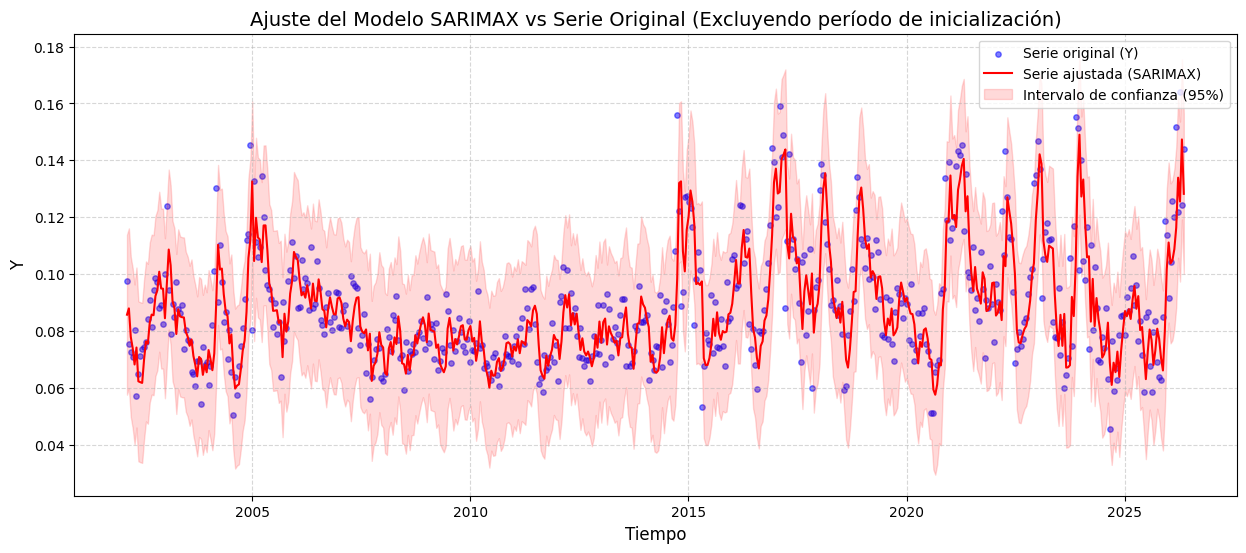

In [8]:
graficos = GraficosAjuste()
graficos.ajuste_vs_datos(temperatura_cubo.tiempo, temperatura_cubo.datos[0, 0, :], vegetacion_cubo.datos[0, 0, :], ajuste)

## SARIMAX + DLM

In [9]:

def matriz_lags(x, L0=0, L1=2):
    """
    Genera una matriz de retardos para la variable x desde el lag L0 hasta el lag L1.
    """
    x = np.asarray(x)
    n = len(x)
    # El retardo máximo determina cuántas observaciones perdemos al inicio
    Z = np.column_stack([
        x[L1-lag:n-lag] if lag > 0 else x[L1:n]
        for lag in range(L0, L1+1)
    ])
    return Z, np.arange(L1, n)

L0 = 1
L1 = 6
L = L1 - L0 + 1
Xlags, idx = matriz_lags(temperatura_cubo.datos[0, 0, :], L0, L1)
# Convertimos Y a un array de numpy antes de indexar con el array idx
Y_dlm = np.asarray(vegetacion_cubo.datos[0, 0, :])[idx]
X = np.array(temperatura_cubo.datos[0, 0, :])
print(Xlags.shape)


(598, 6)


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.177
Model:                            OLS   Adj. R-squared:                  0.169
Method:                 Least Squares   F-statistic:                     21.23
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           1.27e-22
Time:                        19:10:40   Log-Likelihood:                 1535.1
No. Observations:                 598   AIC:                            -3056.
Df Residuals:                     591   BIC:                            -3026.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0743      0.002     33.783      0.0

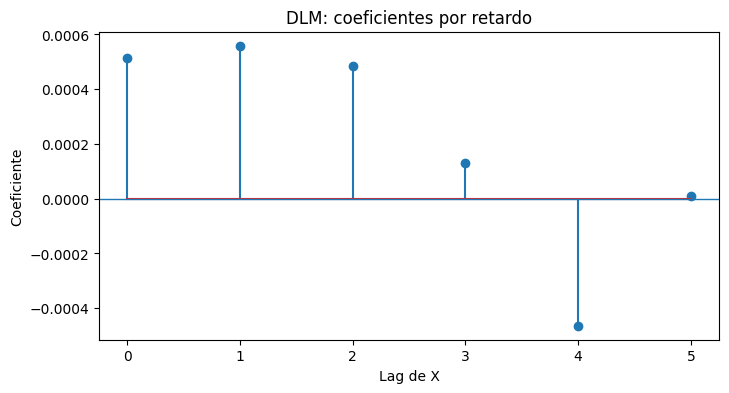

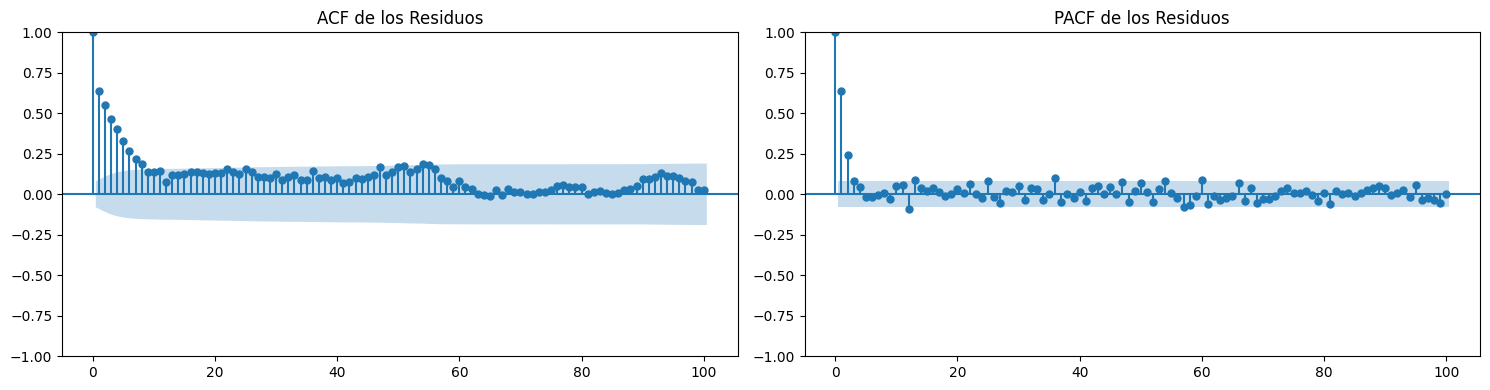

In [10]:
dlm = sm.OLS(Y_dlm, sm.add_constant(Xlags)).fit()
print(dlm.summary())

beta_dlm = dlm.params[1:]

plt.figure(figsize=(8,4))
plt.stem(np.arange(L), beta_dlm)
plt.axhline(0, linewidth=1)
plt.xlabel("Lag de X")
plt.ylabel("Coeficiente")
plt.title("DLM: coeficientes por retardo")
plt.show()

# Gráficos de ACF y PACF de los residuos del DLM
ajuste_sarimax = AjusteSARIMAX(vegetacion_cubo.datos[0, 0, :], dlm, "Ajuste SARIMAX")
ajuste_sarimax.graficos_residuos()

                                      SARIMAX Results                                       
Dep. Variable:                                    y   No. Observations:                  598
Model:             SARIMAX(1, 0, 0)x(1, 0, [1], 23)   Log Likelihood                1557.046
Date:                              Sun, 25 Oct 2026   AIC                          -3094.091
Time:                                      19:15:20   BIC                          -3050.565
Sample:                                           0   HQIC                         -3077.114
                                              - 598                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0005      0.000      1.531      0.126      -0.000       0.001
x2             0.00

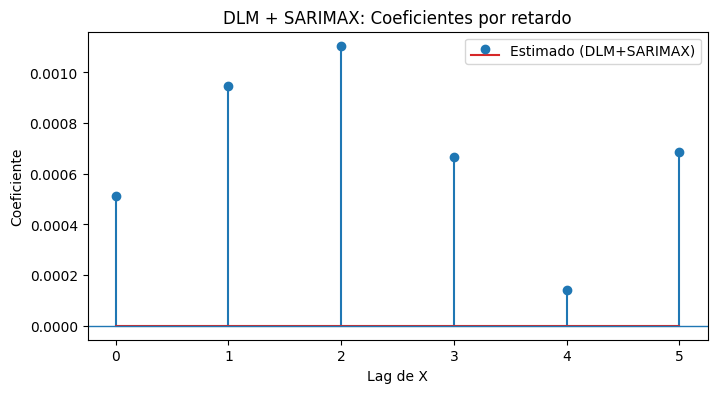

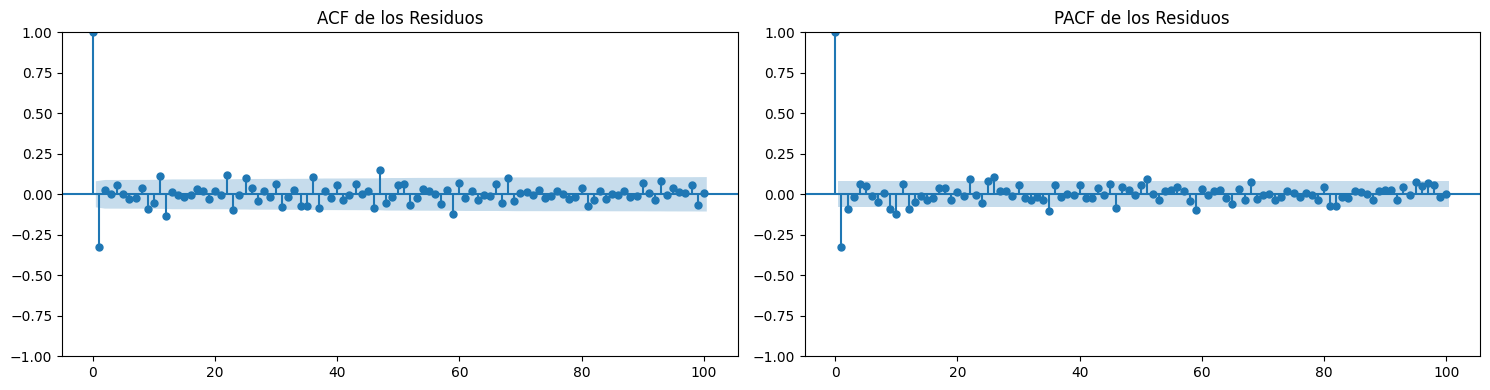

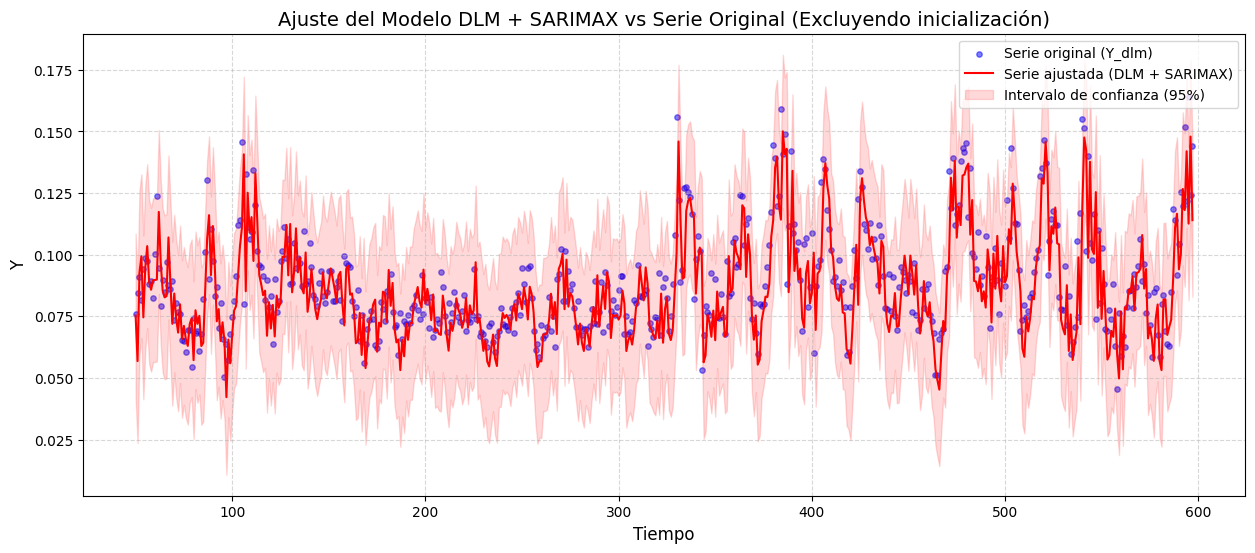

In [17]:
modelo_dlm_sarimax = SARIMAX(
    Y_dlm,
    exog=Xlags,
    order=(1, 0, 0),
    seasonal_order=(1, 0, 1, 23),
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
)

ajuste_dlm_sarimax = modelo_dlm_sarimax.fit(disp=False)
print(ajuste_dlm_sarimax.summary())

# Obtener coeficientes estimados para los retardos
beta_sarimax = ajuste_dlm_sarimax.params[:L]

# Gráfica de coeficientes por retardo
plt.figure(figsize=(8,4))
plt.stem(np.arange(L), beta_sarimax, label="Estimado (DLM+SARIMAX)")
plt.axhline(0, linewidth=1)
plt.xlabel("Lag de X")
plt.ylabel("Coeficiente")
plt.title("DLM + SARIMAX: Coeficientes por retardo")
plt.legend()
plt.show()

ajuste_sarimax = AjusteSARIMAX(vegetacion_cubo.datos[0, 0, :], ajuste_dlm_sarimax, "Ajuste SARIMAX")
ajuste_sarimax.graficos_residuos(lags=100)

# 2. Serie temporal ajustada vs Serie Original
prediccion = ajuste_dlm_sarimax.get_prediction(exog=Xlags)
pred_media = prediccion.predicted_mean
pred_ci = prediccion.conf_int(alpha=0.05)

# Omitimos las primeras 50 observaciones debido a la inicialización con s=23
start_idx = 50
tiempo_grafico = range(start_idx, len(Y_dlm))

plt.figure(figsize=(15, 6))
plt.scatter(tiempo_grafico, np.array(Y_dlm)[start_idx:], color='blue', alpha=0.5, s=15, label="Serie original (Y_dlm)")
plt.plot(tiempo_grafico, pred_media[start_idx:], color='red', label="Serie ajustada (DLM + SARIMAX)", linewidth=1.5)
plt.fill_between(tiempo_grafico, pred_ci[start_idx:, 0], pred_ci[start_idx:, 1], color='red', alpha=0.15, label="Intervalo de confianza (95%)")

plt.title("Ajuste del Modelo DLM + SARIMAX vs Serie Original (Excluyendo inicialización)", fontsize=14)
plt.xlabel("Tiempo", fontsize=12)
plt.ylabel("Y", fontsize=12)
plt.legend(loc="upper right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  598
Model:               SARIMAX(3, 0, 0)   Log Likelihood                1684.381
Date:                Sun, 25 Oct 2026   AIC                          -3348.761
Time:                        19:12:16   BIC                          -3304.876
Sample:                             0   HQIC                         -3331.671
                                - 598                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0004      0.000      1.444      0.149      -0.000       0.001
x2             0.0006      0.000      2.313      0.021     8.7e-05       0.001
x3             0.0004      0.000      1.577      0.1

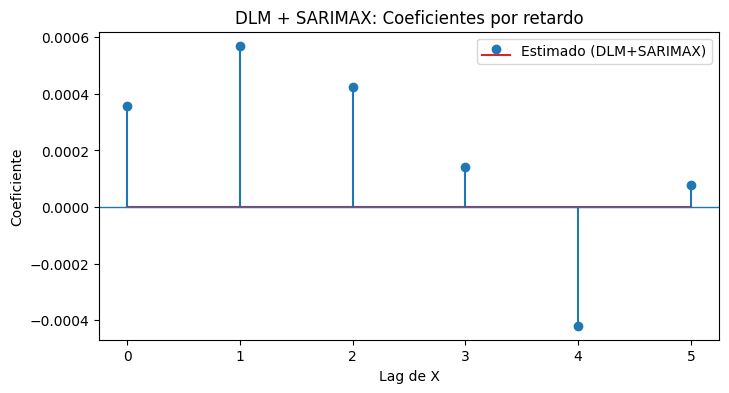

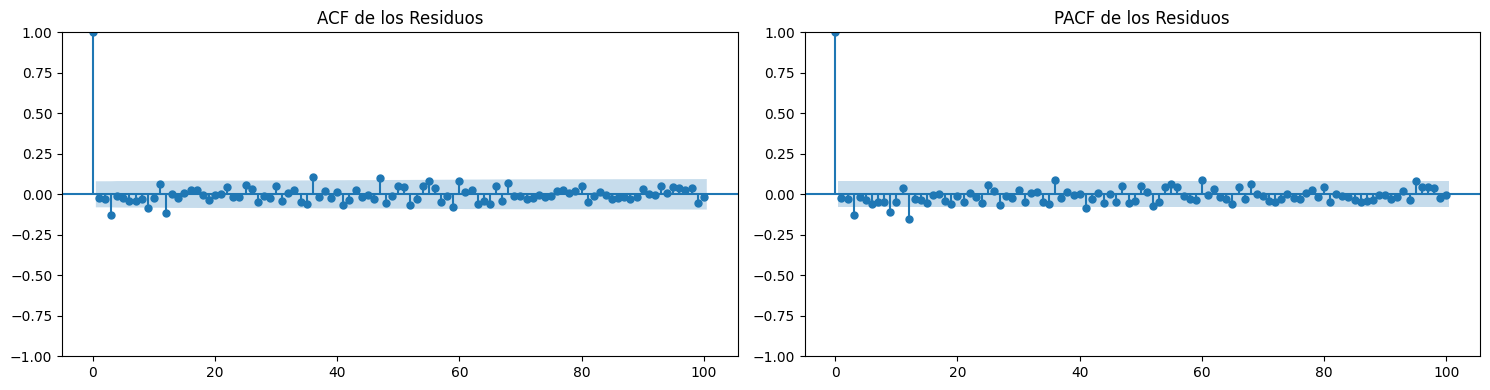

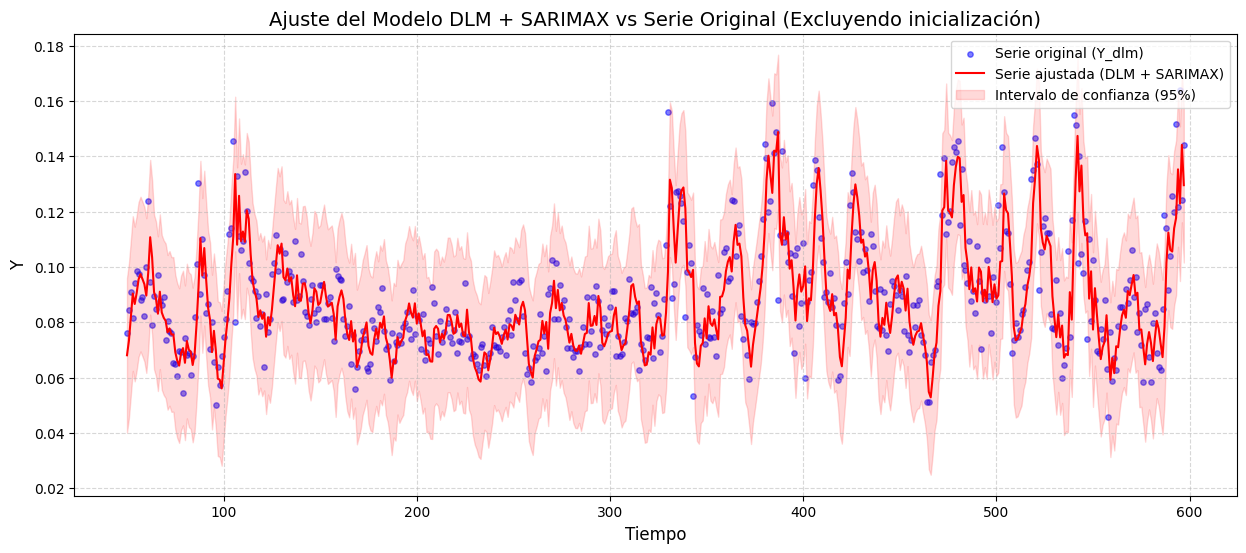

In [16]:
modelo_dlm_sarimax = SARIMAX(
    Y_dlm,
    exog=Xlags,
    order=(3, 0, 0),
    seasonal_order=(0, 0, 0, 23),
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
)

ajuste_dlm_sarimax = modelo_dlm_sarimax.fit(disp=False)
print(ajuste_dlm_sarimax.summary())

# Obtener coeficientes estimados para los retardos
beta_sarimax = ajuste_dlm_sarimax.params[:L]

# Gráfica de coeficientes por retardo
plt.figure(figsize=(8,4))
plt.stem(np.arange(L), beta_sarimax, label="Estimado (DLM+SARIMAX)")
plt.axhline(0, linewidth=1)
plt.xlabel("Lag de X")
plt.ylabel("Coeficiente")
plt.title("DLM + SARIMAX: Coeficientes por retardo")
plt.legend()
plt.show()

ajuste_sarimax = AjusteSARIMAX(vegetacion_cubo.datos[0, 0, :], ajuste_dlm_sarimax, "Ajuste SARIMAX")
ajuste_sarimax.graficos_residuos(lags=100)

# 2. Serie temporal ajustada vs Serie Original
prediccion = ajuste_dlm_sarimax.get_prediction(exog=Xlags)
pred_media = prediccion.predicted_mean
pred_ci = prediccion.conf_int(alpha=0.05)

# Omitimos las primeras 50 observaciones debido a la inicialización con s=23
start_idx = 50
tiempo_grafico = range(start_idx, len(Y_dlm))

plt.figure(figsize=(15, 6))
plt.scatter(tiempo_grafico, np.array(Y_dlm)[start_idx:], color='blue', alpha=0.5, s=15, label="Serie original (Y_dlm)")
plt.plot(tiempo_grafico, pred_media[start_idx:], color='red', label="Serie ajustada (DLM + SARIMAX)", linewidth=1.5)
plt.fill_between(tiempo_grafico, pred_ci[start_idx:, 0], pred_ci[start_idx:, 1], color='red', alpha=0.15, label="Intervalo de confianza (95%)")

plt.title("Ajuste del Modelo DLM + SARIMAX vs Serie Original (Excluyendo inicialización)", fontsize=14)
plt.xlabel("Tiempo", fontsize=12)
plt.ylabel("Y", fontsize=12)
plt.legend(loc="upper right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Causalidad de Granger

In [13]:
datos = np.column_stack([vegetacion_cubo.datos[0, 0, :], temperatura_cubo.datos[0, 0, :]])

# statsmodels en versiones actuales no requiere/admite el parámetro 'verbose'
res = grangercausalitytests(datos, maxlag=46)

print("\nlag    p-valor (SSR F-test)")
for lag in range(1, 47):
    p = res[lag][0]["ssr_ftest"][1]
    print(f"{lag:3d}    {p:.6g}")


Granger Causality
number of lags (no zero) 1
ssr based F test:         F=24.0795 , p=0.0000  , df_denom=600, df_num=1
ssr based chi2 test:   chi2=24.1999 , p=0.0000  , df=1
likelihood ratio test: chi2=23.7269 , p=0.0000  , df=1
parameter F test:         F=24.0795 , p=0.0000  , df_denom=600, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=11.1845 , p=0.0000  , df_denom=597, df_num=2
ssr based chi2 test:   chi2=22.5563 , p=0.0000  , df=2
likelihood ratio test: chi2=22.1440 , p=0.0000  , df=2
parameter F test:         F=11.1845 , p=0.0000  , df_denom=597, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=9.7380  , p=0.0000  , df_denom=594, df_num=3
ssr based chi2 test:   chi2=29.5583 , p=0.0000  , df=3
likelihood ratio test: chi2=28.8545 , p=0.0000  , df=3
parameter F test:         F=9.7380  , p=0.0000  , df_denom=594, df_num=3

Granger Causality
number of lags (no zero) 4
ssr based F test:         F=8.8668  , p=0.0000  